In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
cal=pd.read_csv("/content/calories_consumed.csv")
cal.columns=["wt_gained","cal_consumed"]
print("first 5 rows:\n",cal.head())
print("\nData Types:\n",cal.dtypes)
print("\nStatistical Summary:\n",cal.describe())

first 5 rows:
    wt_gained  cal_consumed
0        108          1500
1        200          2300
2        900          3400
3        200          2200
4        300          2500

Data Types:
 wt_gained       int64
cal_consumed    int64
dtype: object

Statistical Summary:
          wt_gained  cal_consumed
count    14.000000     14.000000
mean    357.714286   2340.714286
std     333.692495    752.109488
min      62.000000   1400.000000
25%     114.500000   1727.500000
50%     200.000000   2250.000000
75%     537.500000   2775.000000
max    1100.000000   3900.000000


In [ ]:
#BUssiness moment decisions
print("\nMean:\n",cal.mean())


Mean:
 wt_gained        357.714286
cal_consumed    2340.714286
dtype: float64


In [ ]:
#variance
print("\nVariance:\n",cal.var())

#Standard deviation
print("\n standard deviation:\n",cal.std())

#skewness
print("\nSkewness:\n",cal.skew())

#kurtosis
print("\nKurtosis:\n",cal.kurtosis())


Variance:
 wt_gained       111350.681319
cal_consumed    565668.681319
dtype: float64

 standard deviation:
 wt_gained       333.692495
cal_consumed    752.109488
dtype: float64

Skewness:
 wt_gained       1.255737
cal_consumed    0.654930
dtype: float64

Kurtosis:
 wt_gained       0.431272
cal_consumed   -0.290481
dtype: float64


In [ ]:
#correlation
print("\nCorrelation matrix:\n",np.corrcoef(cal.cal_consumed,cal.wt_gained))


Correlation matrix:
 [[1.         0.94699101]
 [0.94699101 1.        ]]


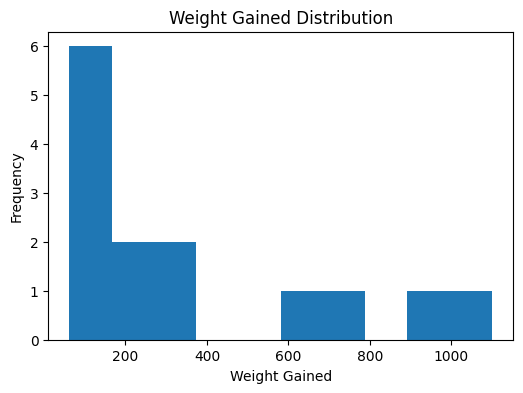

In [ ]:
#univariate analysis
plt.figure(figsize=(6,4))
plt.hist(cal.wt_gained)
plt.title("Weight Gained Distribution")
plt.xlabel("Weight Gained")
plt.ylabel("Frequency")
plt.show()

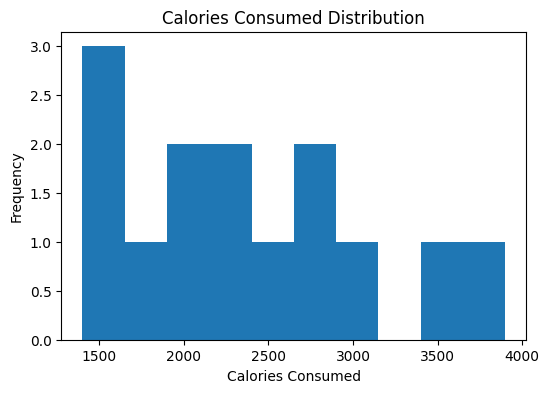

In [ ]:
#histogram - colories consumed
plt.figure(figsize=(6,4))
plt.hist(cal.cal_consumed)
plt.title("Calories Consumed Distribution")
plt.xlabel("Calories Consumed")
plt.ylabel("Frequency")
plt.show()


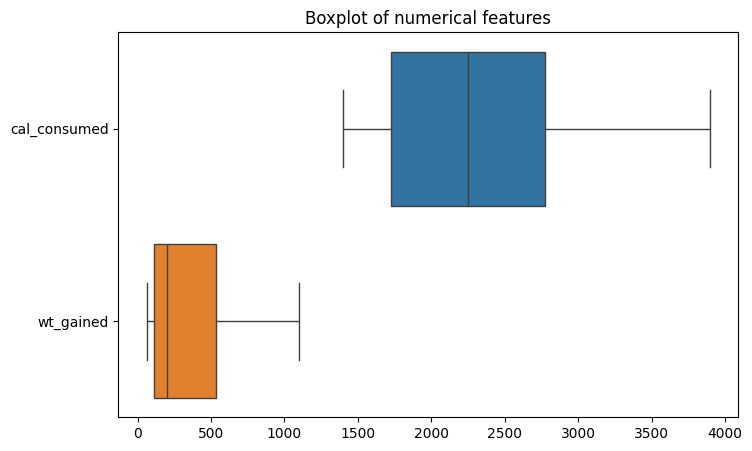

In [ ]:
#Box plot(outlier detection)
plt.figure(figsize=(8,5))
sns.boxplot(data=cal[['cal_consumed','wt_gained']],orient='h')
plt.title("Boxplot of numerical features")
plt.show()

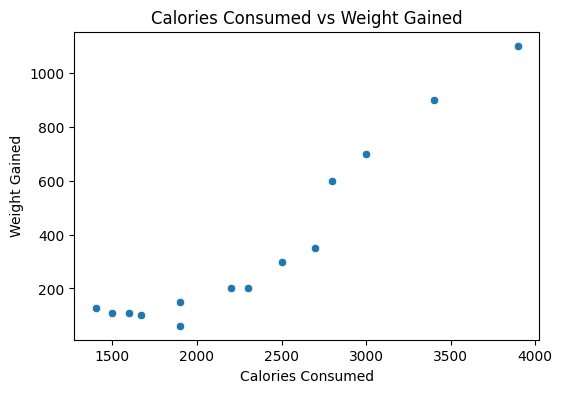

In [ ]:
#Bivariate analysis
plt.figure(figsize=(6,4))
sns.scatterplot(x='cal_consumed',y='wt_gained',data=cal)
plt.title("Calories Consumed vs Weight Gained")
plt.xlabel("Calories Consumed")
plt.ylabel("Weight Gained")
plt.show()

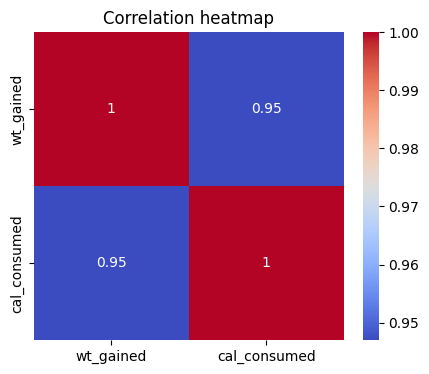

In [ ]:
#correlation heatmap
plt.figure(figsize=(5,4))
sns.heatmap(cal.corr(),annot=True,cmap='coolwarm')
plt.title("Correlation heatmap")
plt.show()

<Figure size 1200x400 with 0 Axes>

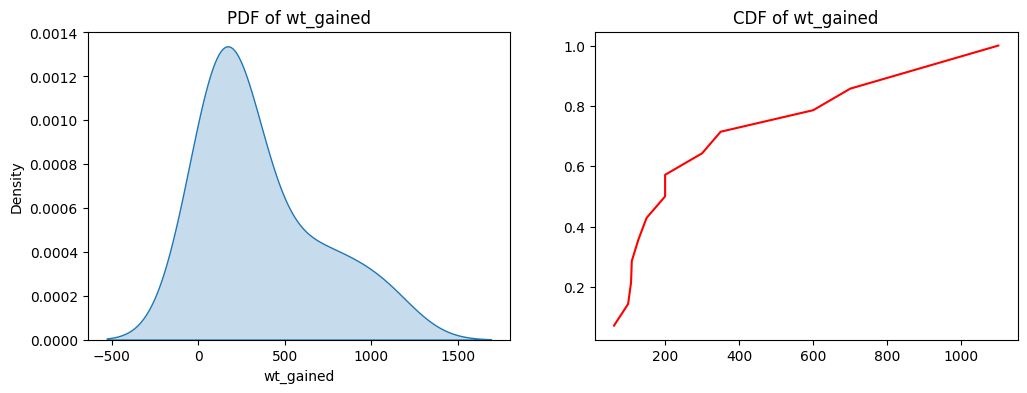

In [ ]:
#pdf & cdf analysis
for col in['cal_consumed','wt_gained']:
  plt.figure(figsize=(12,4))

#pdf
plt.subplot(1,2,1)
sns.kdeplot(cal[col],fill=True)
plt.title(f'PDF of {col}')

#CDF
plt.subplot(1,2,2)
sorted_vals=np.sort(cal[col])
y=np.arange(1,len(sorted_vals)+1)/len(sorted_vals)
plt.plot(sorted_vals,y,color='red')
plt.title(f'CDF of {col}')
plt.show()

In [ ]:
!pip install feature_engine
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from scipy.stats import skew
from feature_engine.outliers import Winsorizer


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 19.2 MB/s eta 0:00:00


In [ ]:
cal=pd.read_csv("/content/calories_consumed.csv")
cal.columns=["wt_gained","cal_consumed"]
print("Initial shape:",cal.shape)
print(cal.head())

Initial shape: (14, 2)
   wt_gained  cal_consumed
0        108          1500
1        200          2300
2        900          3400
3        200          2200
4        300          2500


In [ ]:
print("\nMissing values before treatement:\n",cal.isnull().sum())


Missing values before treatement:
 wt_gained       0
cal_consumed    0
dtype: int64


In [ ]:
for col in cal.columns:
  cal[col] = cal[col].fillna(cal[col].median())
  print("\nMissing values after Treatement:\n",cal.isnull().sum())


Missing values after Treatement:
 wt_gained       0
cal_consumed    0
dtype: int64

Missing values after Treatement:
 wt_gained       0
cal_consumed    0
dtype: int64


In [ ]:
cal.drop_duplicates(inplace=True)
print("\nShape after removing duplicated:",cal.shape)


Shape after removing duplicated: (14, 2)


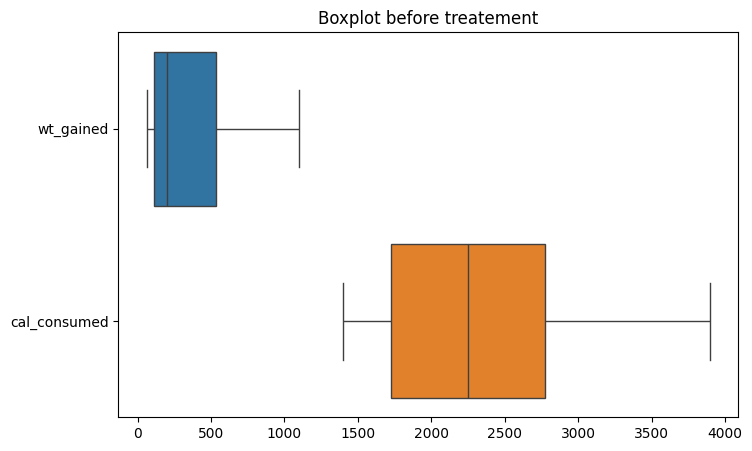

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=cal,orient='h')
plt.title("Boxplot before treatement")
plt.show()

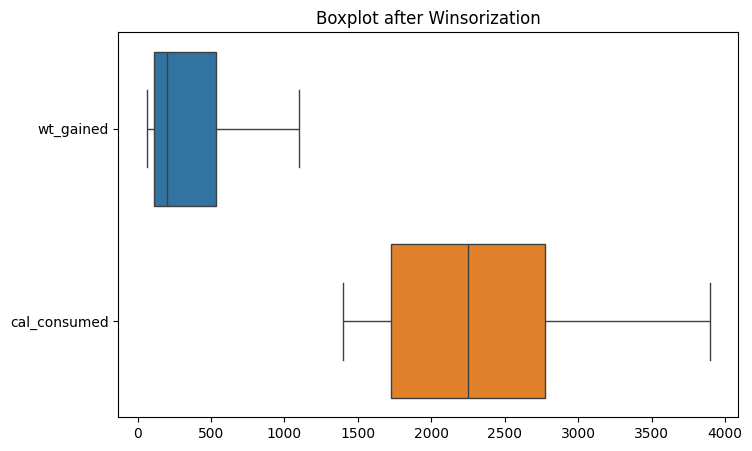

In [ ]:
winsor=Winsorizer(
    capping_method='iqr',
    tail='both',
    fold=1.5,
    variables=['wt_gained','cal_consumed']
)

cal[['cal_consumed','wt_gained']]=winsor.fit_transform(
    cal[['cal_consumed','wt_gained']]
)

plt.figure(figsize=(8,5))
sns.boxplot(data=cal,orient='h')
plt.title("Boxplot after Winsorization")
plt.show()

In [ ]:
print("\nSkewness:\n",cal.skew())


Skewness:
 wt_gained       1.255737
cal_consumed    0.654930
dtype: float64


In [ ]:
#final data preprocessing summary
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
model1=smf.ols('wt_gained ~ cal_consumed',data=cal).fit()
pred1=model1.predict(cal)

rmse1=np.sqrt(np.mean((cal['wt_gained']-pred1)**2))
print(" SLR RMSE:",rmse1)

model1.summary()

 SLR RMSE: 103.30250194726935


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              wt_gained   R-squared:                       0.897
Model:                            OLS   Adj. R-squared:                  0.888
Method:                 Least Squares   F-statistic:                     104.3
Date:                Tue, 02 Jun 2026   Prob (F-statistic):           2.86e-07
Time:                        12:19:58   Log-Likelihood:                -84.792
No. Observations:                  14   AIC:                             173.6
Df Residuals:                      12   BIC:                             174.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     -625.7524    100.823     -6.206      0.000    -845.427    -406.078
cal_consumed     0.4202      0.041     10.211      0.000       0.331       0.510
==============================================================================
Omnibus:                        3.394   Durbin-Watson:                   2.537
Prob(Omnibus):                  0.183   Jarque-Bera (JB):                1.227
Skew:                          -0.203   Prob(JB):                        0.541
Kurtosis:                       1.608   Cond. No.                     8.28e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.28e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
#Log model
model2=smf.ols('wt_gained ~ np.log(cal_consumed)',data=cal).fit()
pred2=model2.predict(cal)

rmse2=np.sqrt(np.mean((cal['wt_gained']-pred2)**2))
print(" Log-x Model RMSE:",rmse2)

model2.summary()

 Log-x Model RMSE: 141.00538169425104


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              wt_gained   R-squared:                       0.808
Model:                            OLS   Adj. R-squared:                  0.792
Method:                 Least Squares   F-statistic:                     50.40
Date:                Tue, 02 Jun 2026   Prob (F-statistic):           1.25e-05
Time:                        12:32:33   Log-Likelihood:                -89.148
No. Observations:                  14   AIC:                             182.3
Df Residuals:                      12   BIC:                             183.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept            -6955.6501   1030.908     -6.747      0.000   -9201.806   -4709.494
np.log(cal_consumed)   948.3717    133.580      7.100      0.000     657.325    1239.418
==============================================================================
Omnibus:                        3.265   Durbin-Watson:                   2.438
Prob(Omnibus):                  0.195   Jarque-Bera (JB):                1.139
Skew:                           0.046   Prob(JB):                        0.566
Kurtosis:                       1.606   Cond. No.                         199.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
#exponential model
model3=smf.ols('np.log(wt_gained) ~ cal_consumed',data=cal).fit()
pred3=np.exp(model3.predict(cal))

rmse3=np.sqrt(np.mean((cal.wt_gained - pred3)**2))
print("Exponential model rmse:,rmse3")
model3.summary()

Exponential model rmse:,rmse3


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      np.log(wt_gained)   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.867
Method:                 Least Squares   F-statistic:                     86.04
Date:                Tue, 02 Jun 2026   Prob (F-statistic):           8.02e-07
Time:                        12:37:58   Log-Likelihood:                -3.3244
No. Observations:                  14   AIC:                             10.65
Df Residuals:                      12   BIC:                             11.93
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        2.8387      0.299      9.479      0.000       2.186       3.491
cal_consumed     0.0011      0.000      9.276      0.000       0.001       0.001
==============================================================================
Omnibus:                       10.165   Durbin-Watson:                   3.130
Prob(Omnibus):                  0.006   Jarque-Bera (JB):                6.120
Skew:                          -1.240   Prob(JB):                       0.0469
Kurtosis:                       5.083   Cond. No.                     8.28e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.28e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
#polynomial model
model4=smf.ols('np.log(wt_gained) ~ cal_consumed + I(cal_consumed**2)',
data=cal).fit()
pred4=np.exp(model4.predict(cal))

rmse4=np.sqrt(np.mean((cal.wt_gained - pred4)**2))
print("Polynomial model rmse:",rmse4)
model4.summary()

Polynomial model rmse: 117.41450013064909


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      np.log(wt_gained)   R-squared:                       0.878
Model:                            OLS   Adj. R-squared:                  0.855
Method:                 Least Squares   F-statistic:                     39.44
Date:                Tue, 02 Jun 2026   Prob (F-statistic):           9.61e-06
Time:                        12:39:33   Log-Likelihood:                -3.3243
No. Observations:                  14   AIC:                             12.65
Df Residuals:                      11   BIC:                             14.57
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                2.8287      1.062      2.664      0.022       0.492       5.165
cal_consumed             0.0011      0.001      1.297      0.221      -0.001       0.003
I(cal_consumed ** 2) -1.675e-09   1.71e-07     -0.010      0.992   -3.77e-07    3.74e-07
==============================================================================
Omnibus:                       10.177   Durbin-Watson:                   3.131
Prob(Omnibus):                  0.006   Jarque-Bera (JB):                6.133
Skew:                          -1.240   Prob(JB):                       0.0466
Kurtosis:                       5.088   Cond. No.                     8.12e+07
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.12e+07. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [ ]:
#model comparison
results=pd.DataFrame({
    "Model":["SLR","Log-x","Exponential","Polynomial"],
    "RMSE":[rmse1,rmse2,rmse3,rmse4],
    "R_squared":[
        model1.rsquared,
        model2.rsquared,
        model3.rsquared,
        model4.rsquared

    ]
})

print("\nModel Comparision:\n",results)


Model Comparision:
          Model        RMSE  R_squared
0          SLR  103.302502   0.896792
1        Log-x  141.005382   0.807707
2  Exponential  118.045157   0.877601
3   Polynomial  117.414500   0.877602


In [ ]:
best_model_name=results.sort_values("RMSE").iloc[0]["Model"]
print("\nBest Model Based on RMSE:",best_model_name)

train, test = train_test_split(cal,test_size=0.3,random_state=42)
final_model=smf.ols('wt_gained ~ cal_consumed',data=train).fit()

train_pred=final_model.predict(train)
test_pred=final_model.predict(test)

train_rmse=np.sqrt(np.mean((train.wt_gained - train_pred)**2))
test_rmse=np.sqrt(np.mean((test.wt_gained - test_pred)**2))

print("\nRMSE of train data:",train_rmse)
print("\nRMSE of test data:",test_rmse)


Best Model Based on RMSE: SLR

RMSE of train data: 105.4862244986957

RMSE of test data: 101.59575681603214


In [ ]:
#Bussiness impact on the project
#########################################
'''Business Impact of the Project'''
###############################
''' Calories Consumed vs Weight Gained Analysis
1️ Data-Driven Diet Planning
The model shows a strong positive relationship between calorie intake and weight gain.
About 80–90% of weight variation is explained by calories.
Enables nutritionists to predict expected weight gain for a given calorie intake.
Helps design personalized calorie-controlled diet plans.

2️ Obesity Risk Identification
Individuals consuming higher calories are statistically more likely to gain more weight.
High-risk calorie thresholds can be identified using CDF analysis.
Supports early intervention programs for obesity prevention.

3️ Preventive Healthcare Strategy
Healthcare providers can estimate:
How much weight gain may occur
What calorie limit keeps weight stable
 Reduces risk of:
Diabetes
Hypertension
Cardiovascular diseases

4️ Fitness & Wellness Industry Application
Gyms and wellness apps can:
Predict weight gain/loss trends
Provide calorie recommendations
Personalize fitness taget'''

' Calories Consumed vs Weight Gained Analysis\n1️ Data-Driven Diet Planning\nThe model shows a strong positive relationship between calorie intake and weight gain.\nAbout 80–90% of weight variation is explained by calories.\nEnables nutritionists to predict expected weight gain for a given calorie intake.\nHelps design personalized calorie-controlled diet plans.\n\n2️ Obesity Risk Identification\nIndividuals consuming higher calories are statistically more likely to gain more weight.\nHigh-risk calorie thresholds can be identified using CDF analysis.\nSupports early intervention programs for obesity prevention.\n\n3️ Preventive Healthcare Strategy\nHealthcare providers can estimate:\nHow much weight gain may occur\nWhat calorie limit keeps weight stable\n Reduces risk of:\nDiabetes\nHypertension\nCardiovascular diseases\n\n4️ Fitness & Wellness Industry Application\nGyms and wellness apps can:\nPredict weight gain/loss trends\nProvide calorie recommendations\nPersonalize fitness taget'